# EDA: Z-Alizadeh Sani extension dataset (Track A)

Exploratory analysis for the CAD and vessel-level (LAD / LCX / RCA) stenosis models.

Goals: understand the data, check quality, and see which inputs relate to each target.
`Cath` (overall CAD) and `LAD`, `LCX`, `RCA` are **targets only**, never inputs.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # so we can reuse the training code's loaders

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from train_cad import find_dataset, load_data, split_features_targets

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160, "display.max_columns", 60)

df = load_data(find_dataset(None))
X, y, label_cols = split_features_targets(df)
targets = pd.DataFrame(y)            # columns: CAD, LAD, LCX, RCA  (1 = disease / stenosis)
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"{len(df)} patients | {X.shape[1]} input features ({len(num_cols)} numeric, {len(cat_cols)} text) | 4 targets")

303 patients | 55 input features (34 numeric, 21 text) | 4 targets


## 1. Data quality

In [2]:
print("Missing values in inputs:", int(X.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
const = [c for c in X.columns if X[c].nunique() == 1]
print("Constant columns (carry no information):", const)
X.describe().T[["min", "50%", "max"]].round(1).head(12)

Missing values in inputs: 0
Duplicate rows: 0
Constant columns (carry no information): ['Exertional CP']


,min,50%,max
Age,30.0,58.0,86.0
Weight,48.0,74.0,120.0
Length,140.0,165.0,188.0
BMI,18.1,26.8,40.9
DM,0.0,0.0,1.0
HTN,0.0,1.0,1.0
Current Smoker,0.0,0.0,1.0
EX-Smoker,0.0,0.0,1.0
FH,0.0,0.0,1.0
BP,90.0,130.0,190.0


## 2. Class balance of the four targets

,positive,negative,prevalence
CAD,216,87,0.713
LAD,177,126,0.584
LCX,119,184,0.393
RCA,114,189,0.376


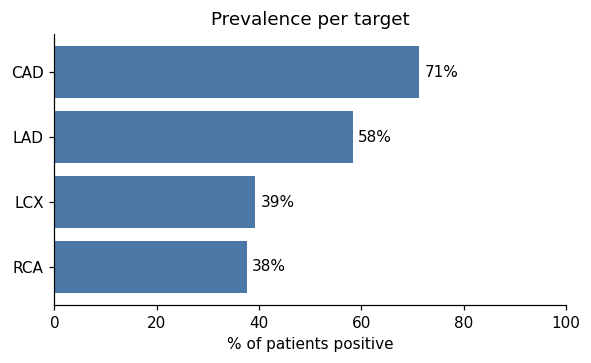

In [3]:
counts = targets.sum().rename("positive").to_frame()
counts["negative"] = len(targets) - counts["positive"]
counts["prevalence"] = (counts["positive"] / len(targets)).round(3)
display(counts)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(counts.index[::-1], counts["prevalence"][::-1] * 100, color="#4C78A8")
for i, v in enumerate(counts["prevalence"][::-1] * 100):
    ax.text(v + 1, i, f"{v:.0f}%", va="center")
ax.set_xlim(0, 100); ax.set_xlabel("% of patients positive")
ax.set_title("Prevalence per target"); plt.show()

LCX and RCA have the fewest positives, so these models have less to learn from and are expected to be harder.
Also note the overall CAD prevalence is high: these are patients who were referred for angiography, not a general population.

## 3. Do the vessel labels agree with overall CAD?

CAD,CAD,Normal
stenotic vessels,,
0,0,86
1,86,1
2,67,0
3,63,0


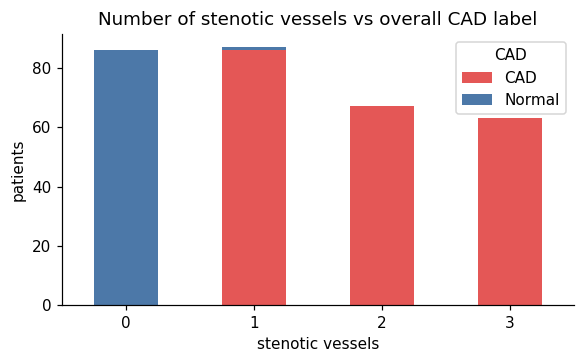

Co-occurrence of vessel stenoses (number of patients with both):


,LAD,LCX,RCA
LAD,177,96,87
LCX,96,119,73
RCA,87,73,114


In [4]:
n_vessels = targets[["LAD", "LCX", "RCA"]].sum(axis=1).rename("stenotic vessels")
tab = pd.crosstab(n_vessels, targets["CAD"].map({0: "Normal", 1: "CAD"}))
display(tab)

fig, ax = plt.subplots(figsize=(6, 3.2))
tab.plot.bar(ax=ax, stacked=True, color=["#E45756", "#4C78A8"], rot=0)
ax.set_ylabel("patients"); ax.set_title("Number of stenotic vessels vs overall CAD label"); plt.show()

print("Co-occurrence of vessel stenoses (number of patients with both):")
display(targets[["LAD", "LCX", "RCA"]].T.dot(targets[["LAD", "LCX", "RCA"]]))

## 4. Numeric features: CAD vs Normal

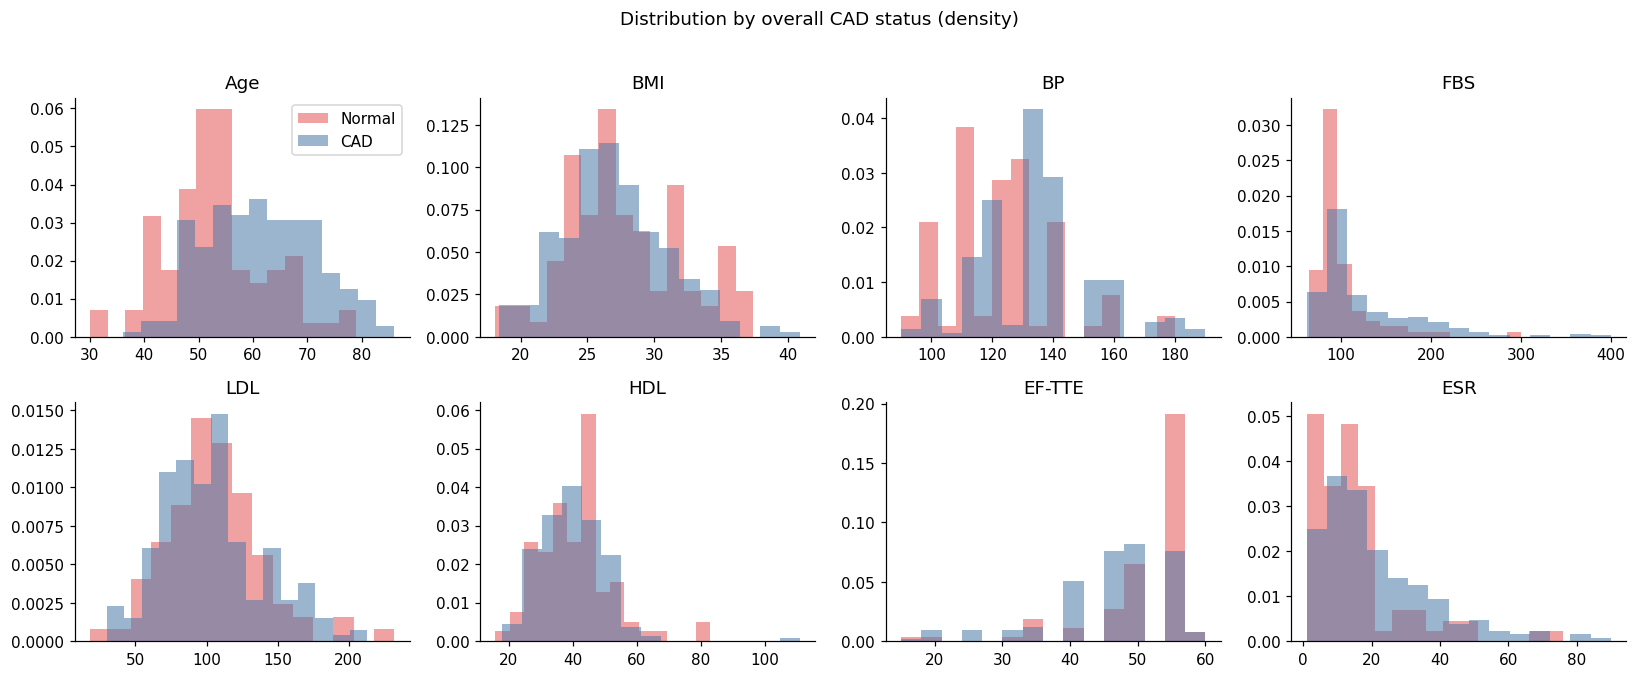

In [5]:
show = ["Age", "BMI", "BP", "FBS", "LDL", "HDL", "EF-TTE", "ESR"]
show = [c for c in show if c in X.columns]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), show):
    for val, name, col in [(0, "Normal", "#E45756"), (1, "CAD", "#4C78A8")]:
        ax.hist(X.loc[targets["CAD"] == val, c], bins=15, alpha=0.55, label=name, color=col, density=True)
    ax.set_title(c)
axes[0, 0].legend()
plt.suptitle("Distribution by overall CAD status (density)", y=1.02); plt.tight_layout(); plt.show()

## 5. Yes/No and categorical features: CAD rate

,feature,value,n,CAD_rate,diff_vs_base
0,Nonanginal,Y,16,0.188,-0.525
1,VHD,Severe,11,0.273,-0.440
2,Q Wave,1,16,1.000,0.287
3,St Elevation,1,14,1.000,0.287
4,Atypical,Y,93,0.430,-0.283
5,Typical Chest Pain,0,139,0.446,-0.267
6,Typical Chest Pain,1,164,0.939,0.226
7,Airway disease,Y,11,0.909,0.196
8,DM,1,90,0.889,0.176
9,BBB,LBBB,13,0.538,-0.174


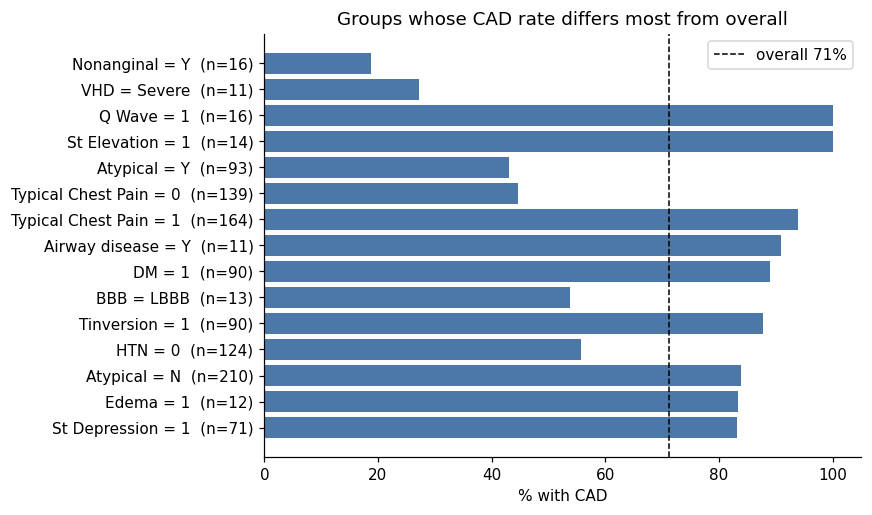

In [6]:
# Share of patients with CAD for each value of each 0/1 or text feature.
rows = []
for c in X.columns:
    vals = X[c].unique()
    if X[c].dtype == "O" or str(X[c].dtype).startswith("str") or set(vals) <= {0, 1}:
        for v in sorted(vals, key=str):
            m = X[c] == v
            if m.sum() >= 10:
                rows.append((c, str(v), int(m.sum()), targets.loc[m, "CAD"].mean()))
rate = pd.DataFrame(rows, columns=["feature", "value", "n", "CAD_rate"])
base = targets["CAD"].mean()
rate["diff_vs_base"] = rate["CAD_rate"] - base
top = rate.reindex(rate["diff_vs_base"].abs().sort_values(ascending=False).index).head(15)
display(top.round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 5))
labels_ = [f"{f} = {v}  (n={n})" for f, v, n in zip(top.feature, top.value, top.n)][::-1]
ax.barh(labels_, top["CAD_rate"][::-1] * 100, color="#4C78A8")
ax.axvline(base * 100, color="k", ls="--", lw=1, label=f"overall {base:.0%}")
ax.set_xlabel("% with CAD"); ax.legend(); ax.set_title("Groups whose CAD rate differs most from overall"); plt.show()

## 6. Which inputs relate to each target?

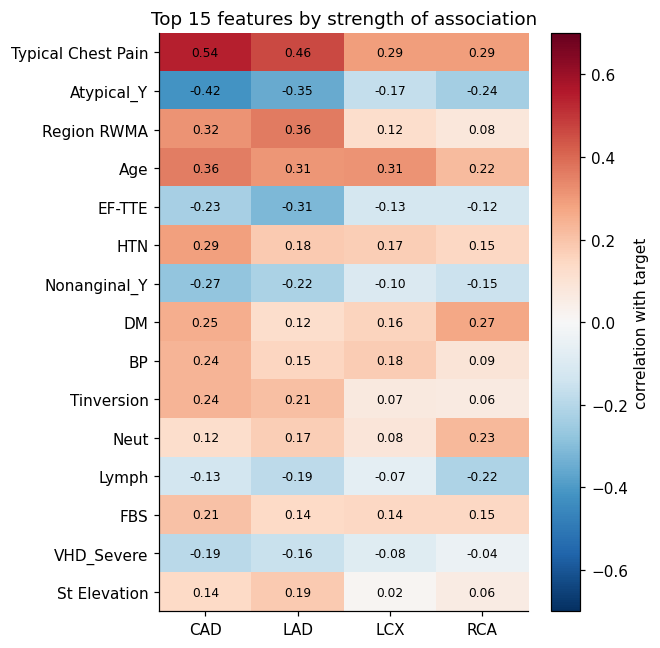

In [7]:
# One-hot encode text columns, then correlate every feature with each target (point-biserial).
Xe = pd.get_dummies(X, drop_first=True).astype(float)
Xe = Xe.loc[:, Xe.nunique() > 1]
corr = pd.DataFrame({t: Xe.corrwith(targets[t]) for t in targets.columns})
top_feats = corr.abs().max(axis=1).sort_values(ascending=False).head(15).index
sel = corr.loc[top_feats]

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(sel.values, cmap="RdBu_r", vmin=-0.7, vmax=0.7, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(sel.columns)
ax.set_yticks(range(len(sel))); ax.set_yticklabels(sel.index)
for i in range(sel.shape[0]):
    for j in range(sel.shape[1]):
        ax.text(j, i, f"{sel.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="correlation with target"); ax.set_title("Top 15 features by strength of association")
plt.tight_layout(); plt.show()

## 7. What this means for modelling

**Findings from this notebook**

- **Data quality:** 303 patients, 55 inputs, no missing values, no duplicate rows. `Exertional CP` is constant (always `N`), so it carries no information (harmless to the models).
- **Labels are consistent:** every patient with CAD has at least one stenotic vessel. Only one patient has a stenotic vessel but a `Normal` overall label.
- **Imbalance:** CAD is 71% of patients, LAD 58%, LCX 39%, RCA 38%. These are patients referred for angiography, so predicted probabilities reflect this population, not the general public.
- **Strongest signals for CAD:** typical chest pain (correlation 0.54; 94% of those patients have CAD vs 45% without), age (0.36), Region RWMA (0.32), hypertension (0.29), diabetes (0.25). Atypical chest pain points the other way.
- **Vessel differences:** LAD relates most to chest pain, Region RWMA and low EF-TTE. RCA relates to diabetes and blood-count features. LCX has no strong single signal (age is highest, 0.31).
- **Why LCX and RCA are harder:** their strongest associations are weaker than for CAD and LAD, and they have fewer positive cases. This matches their lower cross-validated scores.
- **Caution:** some groups are tiny (for example severe valve disease n=11, non-anginal pain n=16), so their rates should not be over-interpreted.